## For the Periphery

Processing sample path: /home/mratman1/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1/cycles:2100000000-max_ptcls:25000-frame_size:400000-system_size:150.0-time_step:0.005-thickness:0.1-diffusion_constant:0.0-force_constant:100.0-initial_type:uniform-division_lengths:1.0,0.8-growth_rates:5e-05,4e-05-initial_cells:50-rng_seed:1712031202
Extracting aspect ratios from path: /home/mratman1/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1/cycles:2100000000-max_ptcls:25000-frame_size:400000-system_size:150.0-time_step:0.005-thickness:0.1-diffusion_constant:0.0-force_constant:100.0-initial_type:uniform-division_lengths:1.0,0.8-growth_rates:5e-05,4e-05-initial_cells:50-rng_seed:1712031202
Extracted aspect ratios from division_lengths - Asp1: 10.0, Asp2: 8.0
Calculating probability for sample path: /home/mratman1/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1/cycles:2100000000-max_ptcls:25000-frame_size:400000-system_size:150.0-time_step

<Figure size 1200x800 with 0 Axes>

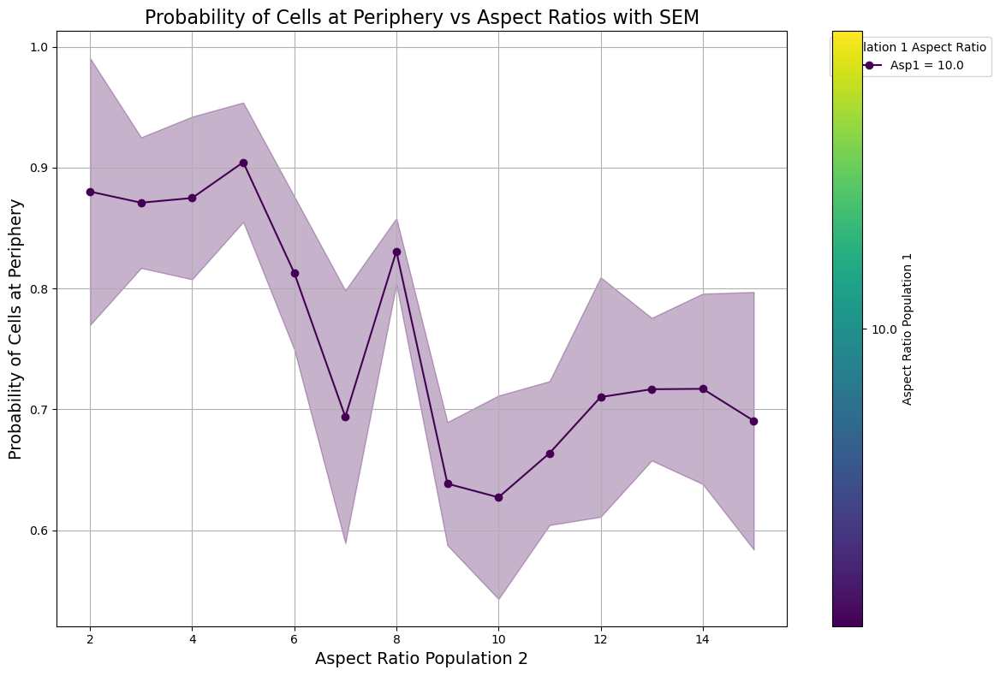

Plotting completed.


In [1]:
import pandas as pd
import numpy as np
import tools.tracking.ancestors as ancestorTracker
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
import matplotlib as mpl
from routines.parameterTable import parameterTable
import re  


radial_persistence_thresh = 10  


basePath = "/home/mratman1/activeMatterCommunities/workspace/simulations_eqdivtime/asp10"
df = parameterTable(basePath)

def extract_aspect_ratios_from_path(path):
    print(f"Extracting aspect ratios from path: {path}")  
    
    match_div = re.search(r'division_lengths:([\d.]+),([\d.]+)', path)
    if match_div:
        asp1 = round(float(match_div.group(1)) / 0.1, 0)
        asp2 = round(float(match_div.group(2)) / 0.1, 0)
        print(f"Extracted aspect ratios from division_lengths - Asp1: {asp1}, Asp2: {asp2}")
        return asp1, asp2
    else:
        
        match_mar = re.search(r'MAR:([\d.]+),([\d.]+)', path)
        if match_mar:
            asp1 = float(match_mar.group(1))
            asp2 = float(match_mar.group(2))
            print(f"Extracted aspect ratios from MAR - Asp1: {asp1}, Asp2: {asp2}")
            return asp1, asp2
        else:
            raise ValueError("Neither 'division_lengths' nor 'MAR' found in path")

def has_consecutive_radial_order(radial_order, threshold, consecutive_thresh):
    """
    Check if there exists a sequence of at least 'consecutive_thresh' consecutive
    timesteps where radial_order > threshold.
    """
    count = 0
    for ro in radial_order:
        if ro > threshold:
            count += 1
            if count >= consecutive_thresh:
                return True
        else:
            count = 0
    return False

def calculate_probability(sample_path):
    print(f"Calculating probability for sample path: {sample_path}")  
    trajectories = ancestorTracker.fetch_trajectories(sample_path)

    total_periphery_cells = 0
    qualified_cells = 0

    for traj in trajectories:
        print(f"Trajectory front displacement (first): {traj.front_displacement[0]}, (last): {traj.front_displacement[-1]}")
        
        if traj.front_displacement[-1] < 0.5 and traj.front_displacement[0] >= 0.5:
            total_periphery_cells += 1

            
            if has_consecutive_radial_order(traj.radial, 0.8, radial_persistence_thresh):
                qualified_cells += 1
                print(f"Trajectory qualified: radial_order > 0.8 for at least {radial_persistence_thresh} consecutive timesteps")
            else:
                print(f"Trajectory did not qualify: radial_order > 0.8 for less than {radial_persistence_thresh} consecutive timesteps")

    print(f"Total periphery cells: {total_periphery_cells}, Qualified cells: {qualified_cells}")
    probability = qualified_cells / total_periphery_cells if total_periphery_cells > 0 else 0
    print(f"Calculated probability: {probability}")
    return probability


probabilities_dict = {}


for sample_path in df.basePath.values:
    print(f"Processing sample path: {sample_path}")  
    
    
    try:
        asp1, asp2 = extract_aspect_ratios_from_path(sample_path)
    except ValueError as e:
        print(f"Error extracting aspect ratios: {e}")
        continue  
    
    
    prob = calculate_probability(sample_path)
    
    
    if asp1 not in probabilities_dict:
        probabilities_dict[asp1] = {}
    
    if asp2 not in probabilities_dict[asp1]:
        probabilities_dict[asp1][asp2] = []
    
    probabilities_dict[asp1][asp2].append(prob)
    print(f"Updated probabilities_dict[{asp1}][{asp2}] with new probability: {prob}")


mean_probs = {}
sem_probs = {}

for asp1, asp2_dict in probabilities_dict.items():
    mean_probs[asp1] = {}
    sem_probs[asp1] = {}
    
    for asp2, probs in asp2_dict.items():
        mean_probs[asp1][asp2] = np.mean(probs)
        sem_probs[asp1][asp2] = np.std(probs, ddof=1) / np.sqrt(len(probs)) if len(probs) > 1 else 0
        print(f"Mean probability for Asp1: {asp1}, Asp2: {asp2} -> {mean_probs[asp1][asp2]}")
        print(f"SEM for Asp1: {asp1}, Asp2: {asp2} -> {sem_probs[asp1][asp2]}")


aspect_ratios_population_1 = sorted(mean_probs.keys())
aspect_ratios_population_2 = sorted(set(asp2 for asp2_dict in mean_probs.values() for asp2 in asp2_dict))


data_to_save = []
for asp1 in aspect_ratios_population_1:
    for asp2, prob in mean_probs[asp1].items():
        data_to_save.append({
            'Aspect_Ratio_Population_1': asp1, 
            'Aspect_Ratio_Population_2': asp2, 
            'Mean_Probability': prob,
            'SEM': sem_probs[asp1][asp2]
        })

df_probabilities = pd.DataFrame(data_to_save)
csv_file_path = "mean_probabilities_with_sem_consecutive.csv"
df_probabilities.to_csv(csv_file_path, index=False)
print(f"Data saved to {csv_file_path}")


plt.figure(figsize=(12, 8))
cmap = plt.get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(aspect_ratios_population_1)))

fig, ax = plt.subplots(figsize=(12, 8))
cmap = plt.get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(aspect_ratios_population_1)))

for i, asp1 in enumerate(aspect_ratios_population_1):
    asp2_values = []
    prob_values = []
    sem_values = []
    
    for asp2 in aspect_ratios_population_2:
        if asp2 in mean_probs[asp1]:
            asp2_values.append(asp2)
            prob_values.append(mean_probs[asp1][asp2])
            sem_values.append(sem_probs[asp1][asp2])
    
    if len(asp2_values) == 0:
        print(f"No data for Asp1: {asp1}")
        continue
    
    print(f"Plotting Asp1: {asp1}, Asp2 values: {asp2_values}, Probabilities: {prob_values}, SEM: {sem_values}")
    ax.plot(asp2_values, prob_values, label=f'Asp1 = {asp1}', color=colors[i], marker='o')
    ax.fill_between(
        asp2_values,
        np.array(prob_values) - np.array(sem_values),
        np.array(prob_values) + np.array(sem_values),
        color=colors[i],
        alpha=0.3
    )


norm = mpl.colors.Normalize(vmin=min(aspect_ratios_population_1), vmax=max(aspect_ratios_population_1))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Aspect Ratio Population 1')
cbar.set_ticks(aspect_ratios_population_1)
cbar.ax.set_yticklabels([str(asp1) for asp1 in aspect_ratios_population_1])

plt.xlabel('Aspect Ratio Population 2', fontsize=14)
plt.ylabel('Probability of Cells at Periphery', fontsize=14)
plt.title('Probability of Cells at Periphery vs Aspect Ratios with SEM', fontsize=16)
plt.legend(title='Population 1 Aspect Ratio', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Plotting completed.")


## For the Bulk

Processing sample path: /home/mratman1/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1/cycles:2100000000-max_ptcls:25000-frame_size:400000-system_size:150.0-time_step:0.005-thickness:0.1-diffusion_constant:0.0-force_constant:100.0-initial_type:uniform-division_lengths:1.0,0.8-growth_rates:5e-05,4e-05-initial_cells:50-rng_seed:1712031202
Extracting aspect ratios from path: /home/mratman1/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1/cycles:2100000000-max_ptcls:25000-frame_size:400000-system_size:150.0-time_step:0.005-thickness:0.1-diffusion_constant:0.0-force_constant:100.0-initial_type:uniform-division_lengths:1.0,0.8-growth_rates:5e-05,4e-05-initial_cells:50-rng_seed:1712031202
Extracted aspect ratios from division_lengths - Asp1: 10.0, Asp2: 8.0
Calculating probability for sample path: /home/mratman1/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1/cycles:2100000000-max_ptcls:25000-frame_size:400000-system_size:150.0-time_step

<Figure size 1200x800 with 0 Axes>

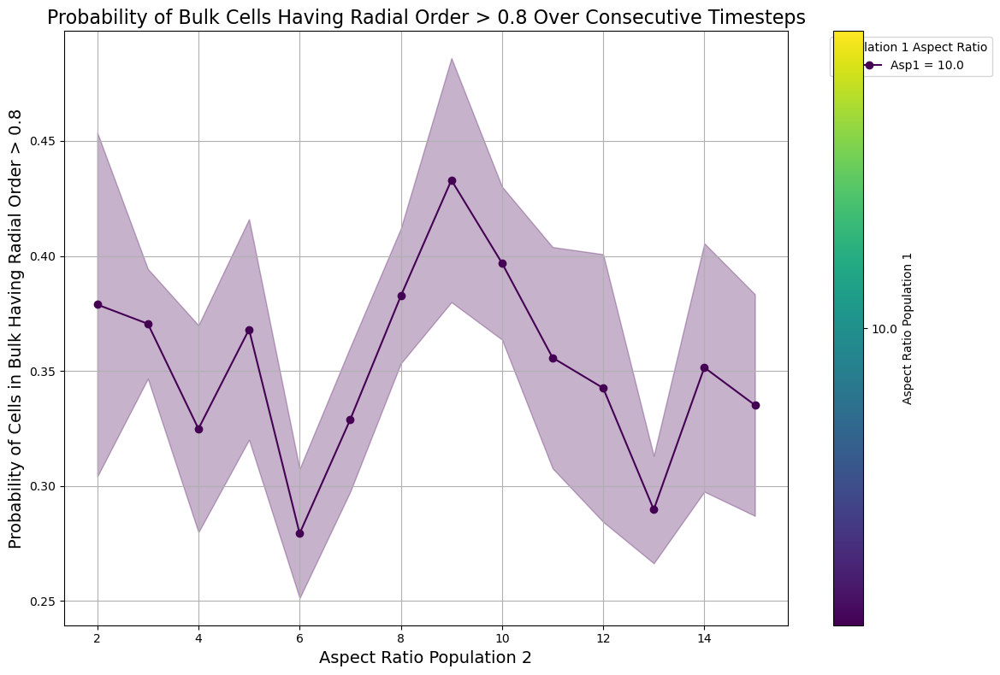

In [ ]:
import pandas as pd
import numpy as np
import tools.tracking.ancestors as ancestorTracker
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
import matplotlib as mpl
from routines.parameterTable import parameterTable
import re  


radial_persistence_thresh = 10  


basePath = "/home/mratman1/activeMatterCommunities/workspace/simulations_eqdivtime/asp10"
df = parameterTable(basePath)

def extract_aspect_ratios_from_path(path):
    print(f"Extracting aspect ratios from path: {path}")  
    
    match_div = re.search(r'division_lengths:([\d.]+),([\d.]+)', path)
    if match_div:
        asp1 = round(float(match_div.group(1)) / 0.1, 0)
        asp2 = round(float(match_div.group(2)) / 0.1, 0)
        print(f"Extracted aspect ratios from division_lengths - Asp1: {asp1}, Asp2: {asp2}")
        return asp1, asp2
    else:
        
        match_mar = re.search(r'MAR:([\d.]+),([\d.]+)', path)
        if match_mar:
            asp1 = float(match_mar.group(1))
            asp2 = float(match_mar.group(2))
            print(f"Extracted aspect ratios from MAR - Asp1: {asp1}, Asp2: {asp2}")
            return asp1, asp2
        else:
            raise ValueError("Neither 'division_lengths' nor 'MAR' found in path")

def has_consecutive_radial_order(radial_order, threshold, consecutive_thresh):
    """
    Check if there exists a sequence of at least 'consecutive_thresh' consecutive
    timesteps where radial_order > threshold.
    """
    count = 0
    for ro in radial_order:
        if ro > threshold:
            count += 1
            if count >= consecutive_thresh:
                return True
        else:
            count = 0
    return False

def calculate_probability(sample_path):
    print(f"Calculating probability for sample path: {sample_path}")  
    trajectories = ancestorTracker.fetch_trajectories(sample_path)

    total_bulk_cells = 0
    qualified_cells = 0

    for traj in trajectories:
        print(f"Trajectory front displacement (first): {traj.front_displacement[0]}, (last): {traj.front_displacement[-1]}")
        
        
        if traj.front_displacement[-1] < 0.5 and traj.front_displacement[0] < 0.5:
            total_bulk_cells += 1

            
            if has_consecutive_radial_order(traj.radial, 0.8, radial_persistence_thresh):
                qualified_cells += 1
                print(f"Trajectory qualified: radial_order > 0.8 for at least {radial_persistence_thresh} consecutive timesteps")
            else:
                print(f"Trajectory did not qualify: radial_order > 0.8 for less than {radial_persistence_thresh} consecutive timesteps")

    print(f"Total bulk cells: {total_bulk_cells}, Qualified cells: {qualified_cells}")
    probability = qualified_cells / total_bulk_cells if total_bulk_cells > 0 else 0
    print(f"Calculated probability: {probability}")
    return probability


probabilities_dict = {}


for sample_path in df.basePath.values:
    print(f"Processing sample path: {sample_path}")  
    
    
    try:
        asp1, asp2 = extract_aspect_ratios_from_path(sample_path)
    except ValueError as e:
        print(f"Error extracting aspect ratios: {e}")
        continue  
    
    
    prob = calculate_probability(sample_path)
    
    
    if asp1 not in probabilities_dict:
        probabilities_dict[asp1] = {}
    
    if asp2 not in probabilities_dict[asp1]:
        probabilities_dict[asp1][asp2] = []
    
    probabilities_dict[asp1][asp2].append(prob)
    print(f"Updated probabilities_dict[{asp1}][{asp2}] with new probability: {prob}")


mean_probs = {}
sem_probs = {}

for asp1, asp2_dict in probabilities_dict.items():
    mean_probs[asp1] = {}
    sem_probs[asp1] = {}
    
    for asp2, probs in asp2_dict.items():
        mean_probs[asp1][asp2] = np.mean(probs)
        sem_probs[asp1][asp2] = np.std(probs, ddof=1) / np.sqrt(len(probs)) if len(probs) > 1 else 0
        print(f"Mean probability for Asp1: {asp1}, Asp2: {asp2} -> {mean_probs[asp1][asp2]}")
        print(f"SEM for Asp1: {asp1}, Asp2: {asp2} -> {sem_probs[asp1][asp2]}")


aspect_ratios_population_1 = sorted(mean_probs.keys())
aspect_ratios_population_2 = sorted(set(asp2 for asp2_dict in mean_probs.values() for asp2 in asp2_dict))


data_to_save = []
for asp1 in aspect_ratios_population_1:
    for asp2, prob in mean_probs[asp1].items():
        data_to_save.append({
            'Aspect_Ratio_Population_1': asp1, 
            'Aspect_Ratio_Population_2': asp2, 
            'Mean_Probability': prob,
            'SEM': sem_probs[asp1][asp2]
        })

df_probabilities = pd.DataFrame(data_to_save)
csv_file_path = "mean_probabilities_bulk_consecutive.csv"
df_probabilities.to_csv(csv_file_path, index=False)
print(f"Data saved to {csv_file_path}")


plt.figure(figsize=(12, 8))
cmap = plt.get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(aspect_ratios_population_1)))

fig, ax = plt.subplots(figsize=(12, 8))
cmap = plt.get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(aspect_ratios_population_1)))

for i, asp1 in enumerate(aspect_ratios_population_1):
    asp2_values = []
    prob_values = []
    sem_values = []
    
    for asp2 in aspect_ratios_population_2:
        if asp2 in mean_probs[asp1]:
            asp2_values.append(asp2)
            prob_values.append(mean_probs[asp1][asp2])
            sem_values.append(sem_probs[asp1][asp2])
    
    if len(asp2_values) == 0:
        print(f"No data for Asp1: {asp1}")
        continue
    
    print(f"Plotting Asp1: {asp1}, Asp2 values: {asp2_values}, Probabilities: {prob_values}, SEM: {sem_values}")
    ax.plot(asp2_values, prob_values, label=f'Asp1 = {asp1}', color=colors[i], marker='o')
    ax.fill_between(
        asp2_values,
        np.array(prob_values) - np.array(sem_values),
        np.array(prob_values) + np.array(sem_values),
        color=colors[i],
        alpha=0.3
    )


norm = mpl.colors.Normalize(vmin=min(aspect_ratios_population_1), vmax=max(aspect_ratios_population_1))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Aspect Ratio Population 1')
cbar.set_ticks(aspect_ratios_population_1)
cbar.ax.set_yticklabels([str(asp1) for asp1 in aspect_ratios_population_1])

plt.xlabel('Aspect Ratio Population 2', fontsize=14)
plt.ylabel('Probability of Cells in Bulk Having Radial Order > 0.8', fontsize=14)
plt.title('Probability of Bulk Cells Having Radial Order > 0.8 Over Consecutive Timesteps', fontsize=16)
plt.legend(title='Population 1 Aspect Ratio', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.tight_layout()
plt.show()


## FINAL PLOTTING CELL BELOW FOR THE PAPER

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl



csv_file_1 = "/home/mratman1/activeMatterCommunities/investigations/mean_periphery_ALL10.csv" 

csv_file_2 = "/home/mratman1/activeMatterCommunities/investigations/mean_bulk_ALL10.csv"  

df1 = pd.read_csv(csv_file_1)
df2 = pd.read_csv(csv_file_2)


df1_sorted = df1.sort_values(by='Aspect_Ratio_Population_2')
df2_sorted = df2.sort_values(by='Aspect_Ratio_Population_2')


asp2_values_1 = df1_sorted['Aspect_Ratio_Population_2']
prob_values_1 = df1_sorted['Mean_Probability']
sem_values_1 = df1_sorted['SEM']

asp2_values_2 = df2_sorted['Aspect_Ratio_Population_2']
prob_values_2 = df2_sorted['Mean_Probability']
sem_values_2 = df2_sorted['SEM']


plt.figure(figsize=(12, 8), dpi=300)  


plt.plot(asp2_values_1, prob_values_1, label='Periphery Cells', color='b', alpha=0.7)
plt.fill_between(asp2_values_1, prob_values_1 - sem_values_1, prob_values_1 + sem_values_1, color='b', alpha=0.2)


plt.plot(asp2_values_2, prob_values_2, label='Bulk Cells', color='r', alpha=0.7)
plt.fill_between(asp2_values_2, prob_values_2 - sem_values_2, prob_values_2 + sem_values_2, color='r', alpha=0.2)





plt.legend(loc='upper right', fontsize=25)  
plt.grid(False)  


plt.xticks(fontsize=26)  
plt.yticks(fontsize=26)  


plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/home/mratman1/activeMatterCommunities/investigations/mean_periphery_ALL10.csv.csv'

## Testing a Different Criterion

In [1]:
import pandas as pd
import numpy as np
import tools.tracking.ancestors as ancestorTracker
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
import matplotlib as mpl
from routines.parameterTable import parameterTable
import re
from importlib import reload
from multiprocessing import Pool  


radial_persistence_thresh = 10  
reload(ancestorTracker)


basePath = "/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10"
df = parameterTable(basePath)

def extract_aspect_ratios_from_path(path):
    match = re.search(r'(division_lengths|MAR):([\d.]+),([\d.]+)', path)
    if match:
        asp1 = round(float(match.group(2)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(2))
        asp2 = round(float(match.group(3)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(3))
        return asp1, asp2
    raise ValueError("Neither 'division_lengths' nor 'MAR' found in path")

def has_consecutive_radial_order(radial_order, threshold, consecutive_thresh):
    return np.any(np.convolve(radial_order > threshold, np.ones(consecutive_thresh, dtype=int), 'valid') == consecutive_thresh)

def calculate_probability(sample_path):
    
    try:
        asp1, asp2 = extract_aspect_ratios_from_path(sample_path)
    except ValueError:
        return None, None, None  

    
    trajectories = ancestorTracker.fetch_trajectories(sample_path)
    
    total_periphery_cells = 0
    qualified_cells = 0

    for traj in trajectories:
        if traj.front_displacement[-1] >= 0.5 and traj.front_displacement[0] >= 0.5:
            total_periphery_cells += 1
            if has_consecutive_radial_order(traj.radial, 0.8, radial_persistence_thresh):
                qualified_cells += 1

    
    probability = qualified_cells / total_periphery_cells if total_periphery_cells > 0 else 0
    return asp1, asp2, probability

def process_sample_path(sample_path):
    return calculate_probability(sample_path)


def parallel_calculation(sample_paths):
    with Pool(processes=4) as pool:  
        results = pool.map(process_sample_path, sample_paths)
    return results


sample_paths = df.basePath.values
results = parallel_calculation(sample_paths)


probabilities_dict = {}


for result in results:
    if result is None:
        continue  
    
    asp1, asp2, prob = result
    
    if asp1 not in probabilities_dict:
        probabilities_dict[asp1] = {}
    
    if asp2 not in probabilities_dict[asp1]:
        probabilities_dict[asp1][asp2] = []
    
    probabilities_dict[asp1][asp2].append(prob)


mean_probs = {}
sem_probs = {}

for asp1, asp2_dict in probabilities_dict.items():
    mean_probs[asp1] = {}
    sem_probs[asp1] = {}
    
    for asp2, probs in asp2_dict.items():
        mean_probs[asp1][asp2] = np.mean(probs)
        sem_probs[asp1][asp2] = np.std(probs, ddof=1) / np.sqrt(len(probs)) if len(probs) > 1 else 0


aspect_ratios_population_1 = sorted(mean_probs.keys())
aspect_ratios_population_2 = sorted(set(asp2 for asp2_dict in mean_probs.values() for asp2 in asp2_dict))


data_to_save = []
for asp1 in aspect_ratios_population_1:
    for asp2, prob in mean_probs[asp1].items():
        data_to_save.append({
            'Aspect_Ratio_Population_1': asp1, 
            'Aspect_Ratio_Population_2': asp2, 
            'Mean_Probability': prob,
            'SEM': sem_probs[asp1][asp2]
        })

df_probabilities = pd.DataFrame(data_to_save)
csv_file_path = "mean_bulk_fixed.csv"
df_probabilities.to_csv(csv_file_path, index=False)
print(f"Data saved to {csv_file_path}")


plt.figure(figsize=(12, 8))
cmap = plt.get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(aspect_ratios_population_1)))

fig, ax = plt.subplots(figsize=(12, 8))
cmap = plt.get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(aspect_ratios_population_1)))

for i, asp1 in enumerate(aspect_ratios_population_1):
    asp2_values = []
    prob_values = []
    sem_values = []
    
    for asp2 in aspect_ratios_population_2:
        if asp2 in mean_probs[asp1]:
            asp2_values.append(asp2)
            prob_values.append(mean_probs[asp1][asp2])
            sem_values.append(sem_probs[asp1][asp2])
    
    if len(asp2_values) == 0:
        continue
    
    ax.plot(asp2_values, prob_values, label=f'Asp1 = {asp1}', color=colors[i], marker='o')
    ax.fill_between(
        asp2_values,
        np.array(prob_values) - np.array(sem_values),
        np.array(prob_values) + np.array(sem_values),
        color=colors[i],
        alpha=0.3
    )


norm = mpl.colors.Normalize(vmin=min(aspect_ratios_population_1), vmax=max(aspect_ratios_population_1))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Aspect Ratio Population 1')
cbar.set_ticks(aspect_ratios_population_1)
cbar.ax.set_yticklabels([str(asp1) for asp1 in aspect_ratios_population_1])

plt.xlabel('Aspect Ratio Population 2', fontsize=14)
plt.ylabel('Probability of Cells at Periphery', fontsize=14)
plt.title('Probability of Cells at Periphery vs Aspect Ratios with SEM', fontsize=16)
plt.legend(title='Population 1 Aspect Ratio', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Plotting completed.")


Process SpawnPoolWorker-1:
Traceback (most recent call last):
Process SpawnPoolWorker-2:
Traceback (most recent call last):
  File "/opt/anaconda3/envs/viewmin/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/opt/anaconda3/envs/viewmin/lib/python3.11/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/opt/anaconda3/envs/viewmin/lib/python3.11/multiprocessing/pool.py", line 114, in worker
    task = get()
           ^^^^^
  File "/opt/anaconda3/envs/viewmin/lib/python3.11/multiprocessing/queues.py", line 367, in get
    return _ForkingPickler.loads(res)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: Can't get attribute 'process_sample_path' on <module '__main__' (built-in)>
  File "/opt/anaconda3/envs/viewmin/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/opt/anaconda3/envs/viewmin/lib/python3.11/multiprocessing/process.py", line 108, in run
   

KeyboardInterrupt: 